# Análisis de precios de alquiler en CABA

## Objetivo

Responder las preguntas del proyecto a partir del dataset limpio generado por `src/cleaning.py` (`python -m src.cleaning`).

## Decisiones metodológicas

- **Moneda común:** todos los precios están en USD. Los avisos en pesos se convirtieron con el dólar MEP del día del scraping.
- **Una fila por departamento:** el dataset conserva el historial de cada aviso. Para comparar barrios se usa solo la publicación más reciente de cada `id`, así cada departamento cuenta una vez.
- **Mediana, no promedio:** la distribución de precios es asimétrica, y unos pocos departamentos muy caros inflan el promedio.
- **Mínimo de 30 departamentos por barrio** para incluirlo en los rankings.

In [1]:
import sys
sys.path.append("..")

import pandas as pd

from src.analysis import (
    resumen_por_ambientes,
    resumen_por_barrio,
    ultima_publicacion,
    usd_m2_por_ambientes_en_barrio,
)
from src.charts import (
    guardar,
    precio_por_ambientes,
    ranking_usd_m2_por_barrio,
    usd_m2_chico_vs_grande,
)

pd.set_option("display.float_format", "{:,.1f}".format)

In [2]:
df = pd.read_parquet("../data/processed/alquileres_limpio.parquet")
deptos = ultima_publicacion(df)

print(f"Publicaciones en el dataset limpio: {len(df):,}")
print(f"Departamentos únicos: {len(deptos):,}")

Publicaciones en el dataset limpio: 52,618
Departamentos únicos: 29,038


## 1. ¿Qué barrios tienen el precio más alto por m²?

Se calcula la mediana del alquiler mensual en USD por m² de cada barrio.

In [3]:
resumen = resumen_por_barrio(deptos)
mediana_caba = deptos["precio_usd_m2"].median()

print(f"Mediana CABA: USD {mediana_caba:.1f} por m²")
print(f"Barrios incluidos: {len(resumen)} de {deptos['barrio'].nunique()}")
resumen

Mediana CABA: USD 10.2 por m²
Barrios incluidos: 40 de 48


,propiedades,comuna,mediana_usd_m2,p25_usd_m2,p75_usd_m2,mediana_precio_usd,mediana_m2
barrio,,,,,,,
Puerto Madero,1409,1,22.7,18.1,28.1,"2,250.0",96.0
Palermo,6734,14,11.8,9.6,15.6,600.0,50.0
Núñez,997,13,11.2,9.4,14.0,551.6,50.0
Belgrano,2998,13,10.8,9.0,13.6,573.3,51.0
Retiro,637,1,10.7,8.3,13.5,622.6,60.0
Recoleta,4476,2,10.2,8.5,12.8,540.2,53.0
Colegiales,547,13,10.1,8.7,12.5,487.9,45.0
Chacarita,198,15,9.9,8.7,11.6,399.4,40.5
Saavedra,307,12,9.8,8.7,11.6,450.5,45.0


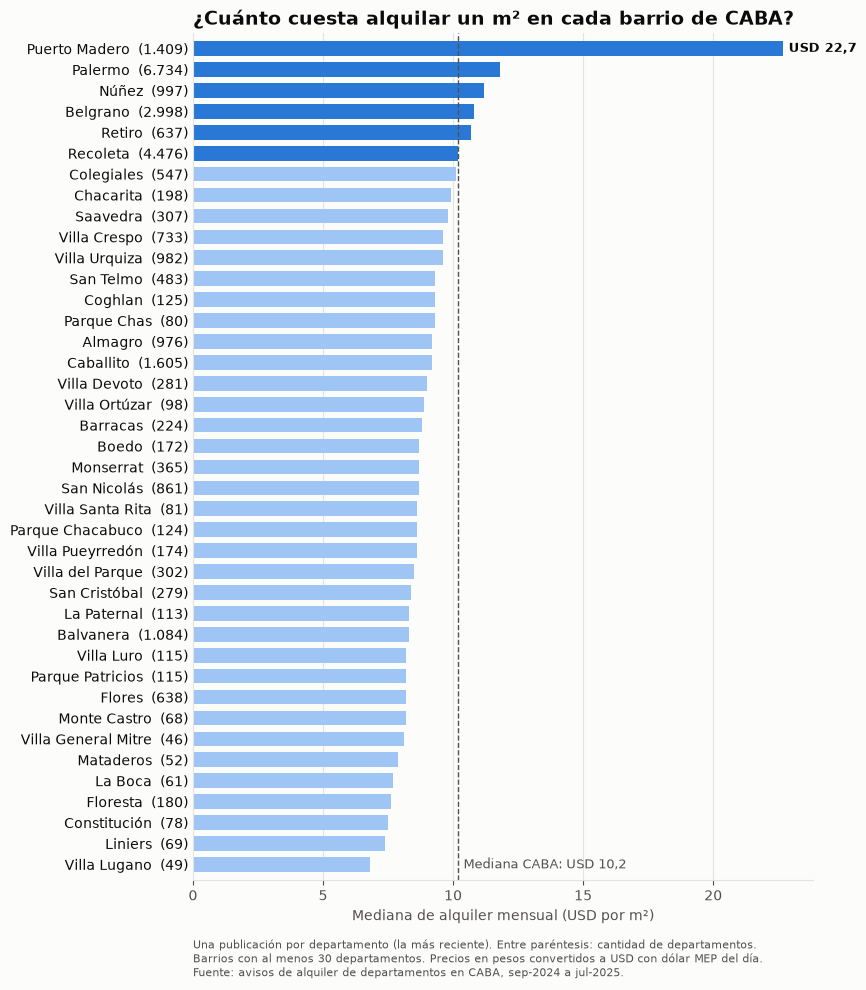

In [4]:
fig = ranking_usd_m2_por_barrio(resumen, mediana_caba)
guardar(fig, "01_usd_m2_por_barrio");

### Conclusiones

- **Puerto Madero es un mercado aparte:** USD 22,7 por m², más del doble de la mediana de CABA (USD 10,2) y casi el doble del segundo barrio, Palermo (USD 11,8). Además sus departamentos son más grandes (mediana de 96 m² contra unos 45 a 50 m² en el resto), así que el alquiler mensual típico llega a USD 2.250.
- **El corredor norte encabeza el ranking:** Palermo, Núñez, Belgrano, Retiro y Recoleta son los únicos barrios por encima de la mediana de la ciudad.
- **Los barrios del sur y del oeste son los más accesibles:** Villa Lugano (USD 6,8), Liniers, Constitución, Floresta y La Boca están entre USD 6,8 y 7,7 por m².
- **Fuera de los extremos, las diferencias son chicas:** más de 30 barrios están entre USD 7,5 y 10 por m². Por ejemplo, entre Chacarita (USD 9,9) y Flores (USD 8,2) hay USD 1,7 por m². En un departamento típico de 45 m², eso son unos USD 75 por mes.

**Limitaciones:** son precios publicados, no precios de cierre. Además, 8 barrios quedaron fuera por tener menos de 30 departamentos publicados: Agronomía, Nueva Pompeya, Parque Avellaneda, Versalles, Villa Real, Villa Riachuelo, Villa Soldati y Vélez Sársfield.

## 2. ¿Cómo influye la cantidad de ambientes en el precio?

Los departamentos de 5 o más ambientes se agrupan en una categoría (`5+`) porque son pocos.

In [5]:
por_ambientes = resumen_por_ambientes(deptos)
por_ambientes

,propiedades,mediana_precio_usd,p25_precio_usd,p75_precio_usd,mediana_m2,mediana_usd_m2,pct_publicado_en_usd,pct_corredor_norte,aumento_vs_anterior_%
ambientes_grupo,,,,,,,,,
1,8137,354.6,290.9,450.0,35.0,10.2,23.2,51.9,NaN
2,11131,454.8,360.4,614.3,46.0,10.1,27.8,56.3,28.3
3,5903,700.0,537.5,"1,200.0",73.0,10.0,39.6,63.8,53.9
4,2428,"1,310.5",778.1,"2,500.0",120.0,11.0,60.8,76.5,87.2
5+,1008,"2,900.0","1,526.2","4,650.0",225.0,12.1,84.1,88.2,121.3


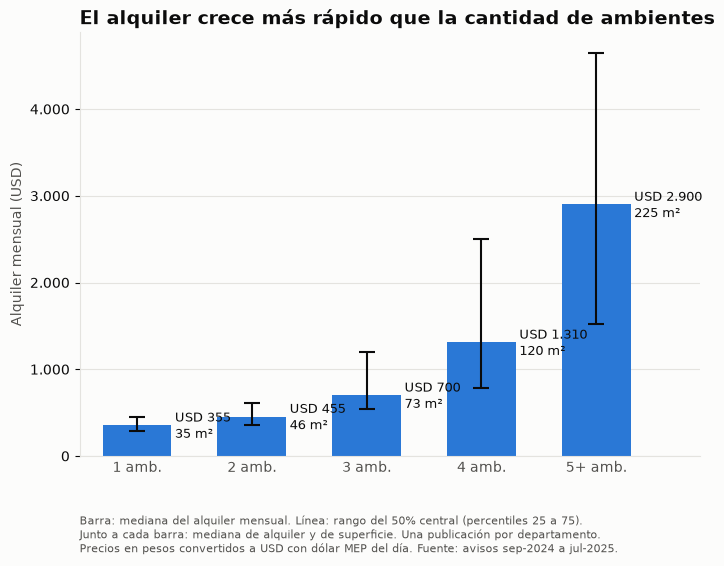

In [6]:
fig = precio_por_ambientes(por_ambientes)
guardar(fig, "02_precio_por_ambientes");

El precio total crece cada vez más rápido: +28% de 1 a 2 ambientes, +54% de 2 a 3, +87% de 3 a 4 y +121% de 4 a 5+.

Sin embargo, la mediana de USD/m² es casi constante entre 1 y 3 ambientes (≈ USD 10) y sube recién en 4 y 5+. La tabla muestra una posible explicación: **los departamentos grandes se concentran en el corredor norte** (52% de los monoambientes contra 88% de los 5+ ambientes) y se publican mayoritariamente en dólares.

Para separar el efecto "tamaño" del efecto "barrio" se compara el USD/m² de 2 y 4 ambientes **dentro de cada barrio**.

In [7]:
chico_vs_grande = usd_m2_por_ambientes_en_barrio(deptos, chico=2, grande=4)
chico_vs_grande

,usd_m2_2_amb,usd_m2_4_amb,diferencia_%
barrio,,,
Almagro,9.2,6.9,-25.7
Villa Crespo,9.6,7.6,-21.0
Balvanera,8.2,6.7,-18.0
Flores,8.0,6.9,-14.3
Colegiales,10.1,8.7,-14.1
San Nicolás,8.5,7.8,-7.9
Villa Urquiza,9.7,9.1,-6.8
Caballito,9.2,8.6,-6.7
Recoleta,10.2,10.0,-1.9


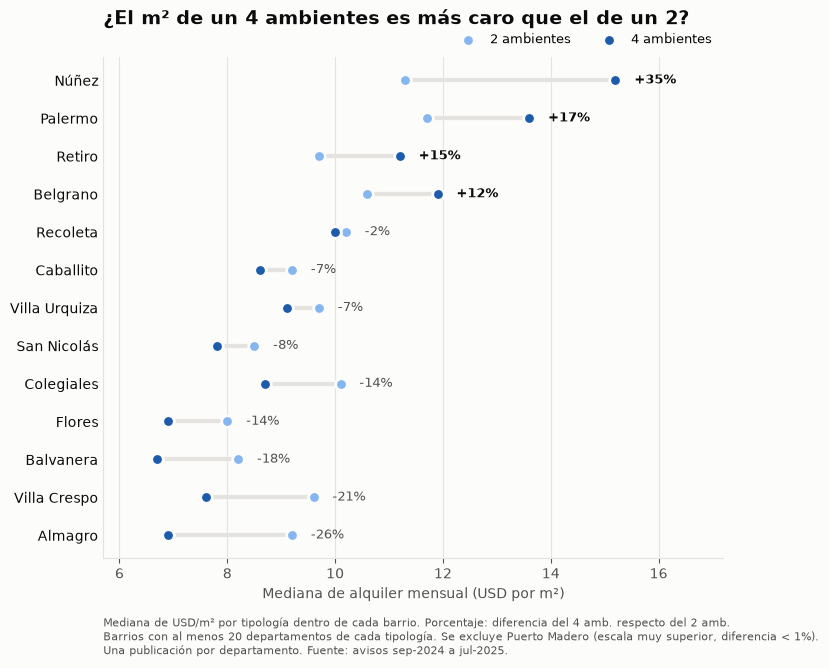

In [8]:
fig = usd_m2_chico_vs_grande(chico_vs_grande, excluir=["Puerto Madero"])
guardar(fig, "03_usd_m2_2_vs_4_ambientes");

### Conclusiones

- **El alquiler crece más rápido que la cantidad de ambientes.** Un 4 ambientes (USD 1.310) cuesta casi 3 veces lo que un 2 ambientes (USD 455), porque tiene 2,6 veces más superficie (120 contra 46 m²).
- **El m² más caro de los departamentos grandes es un efecto de composición, no de tamaño.** Dentro de un mismo barrio, en 9 de los 14 barrios analizados el m² de un 4 ambientes es **más barato** que el de un 2 ambientes: entre 7% y 26% menos en Almagro, Villa Crespo, Balvanera, Flores, Colegiales, San Nicolás, Villa Urquiza y Caballito, y apenas 2% menos en Recoleta.
- **La excepción es el norte premium:** en Núñez (+35%), Palermo (+17%), Retiro (+15%) y Belgrano (+12%) el m² de los departamentos grandes es más caro. Ahí los 4 ambientes suelen ser unidades de categoría (amenities, cochera, torres), un segmento distinto del de los 2 ambientes.
- **Implicancia práctica:** fuera del corredor norte, quien necesita más espacio obtiene más m² por dólar si alquila un departamento más grande, en lugar de pagar el m² más caro de las unidades chicas.

**Limitación:** la comparación por barrio no controla otras características (antigüedad, amenities, cochera) que no están disponibles de forma estructurada en el dataset.